# Build a Recommender System using a Medallion Data Lake

**Name:** Mohd Haider  
**Roll Number:** LCS2023038  
**Institution:** Indian Institute of Information Technology, Lucknow

## Objective
To build a book recommendation system using the Book-Crossing dataset and the Medallion Data Lake architecture. The project follows three layers: Bronze, Silver, and Gold. An item-based collaborative filtering approach using cosine similarity will be used to recommend books.

In [2]:

# ==========================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==========================================

import os
import zipfile
import shutil
import subprocess
import pandas as pd
import numpy as np

from datetime import datetime, timezone

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# ==========================================
# CREATE MEDALLION DATA LAKE STRUCTURE
# ==========================================

folders = ["bronze", "silver", "gold", "raw_data"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(folder, "->", os.path.exists(folder))


Project folders created successfully!
bronze -> True
silver -> True
gold -> True
raw_data -> True


In [4]:

# ==========================================
# DOWNLOAD BOOK-CROSSING DATASET
# ==========================================

repo_url = "https://github.com/ashwanidv100/Recommendation-System---Book-Crossing-Dataset.git"

result = subprocess.run(
    ["git", "clone", "--depth", "1", repo_url, "dataset_repo"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("Dataset repository downloaded successfully!")
else:
    print("Download error:")
    print(result.stderr)


Dataset repository downloaded successfully!


In [5]:

# ==========================================
# LOCATE AND COPY DATASET FILES
# ==========================================

required_files = [
    "BX-Users.csv",
    "BX-Books.csv",
    "BX-Book-Ratings.csv"
]

found_files = {}

for root, dirs, files in os.walk("dataset_repo"):
    for file in required_files:
        if file in files:
            found_files[file] = os.path.join(root, file)

missing_files = [
    file for file in required_files
    if file not in found_files
]

if missing_files:
    print("Missing files:", missing_files)

else:
    for file, source in found_files.items():
        shutil.copy2(
            source,
            os.path.join("raw_data", file)
        )

    print("All dataset files copied successfully!")
    print(os.listdir("raw_data"))


All dataset files copied successfully!
['BX-Books.csv', 'BX-Book-Ratings.csv', 'BX-Users.csv']


In [7]:

# Inspect the problematic area in BX-Books.csv

file_path = "raw_data/BX-Books.csv"

with open(file_path, "r", encoding="latin-1") as file:
    for line_no, line in enumerate(file, start=1):
        if 6449 <= line_no <= 6454:
            print(f"Line {line_no}: {line}")


Line 6449: "0297828991";"Mr Foreigner";"Matthew Kneale";"2003";"Trafalgar Square";"http://images.amazon.com/images/P/0297828991.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0297828991.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0297828991.01.LZZZZZZZ.jpg"

Line 6450: "0061013722";"The Clairvoyant";"Marian Thurm";"1999";"HarperTorch";"http://images.amazon.com/images/P/0061013722.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0061013722.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0061013722.01.LZZZZZZZ.jpg"

Line 6451: "0451163540";"Triple";"Ken Follett";"1991";"Signet Book";"http://images.amazon.com/images/P/0451163540.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0451163540.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0451163540.01.LZZZZZZZ.jpg"

Line 6452: "0735201994";"Peterman Rides Again: Adventures Continue with the Real \"J. Peterman\" Through Life &amp; the Catalog Business";"John Peterman";"2000";"Prentice Hall Art";"http://images.amazon

In [8]:

# ==========================================
# LOAD BOOKS DATASET WITH MALFORMED CSV FIX
# ==========================================

import csv
import pandas as pd

file_path = "raw_data/BX-Books.csv"

rows = []

with open(file_path, "r", encoding="latin-1", newline="") as f:

    reader = csv.reader(
        f,
        delimiter=";",
        quoting=csv.QUOTE_NONE
    )

    header = next(reader)
    expected_columns = len(header)

    extra_fields = 0
    short_rows = 0

    for row in reader:

        # Merge extra fields into the book title
        if len(row) > expected_columns:
            extra_fields += 1
            remaining = expected_columns - 2

            row = [
                row[0],
                ";".join(row[1:len(row)-remaining]),
                *row[len(row)-remaining:]
            ]

        # Fill missing fields without deleting the record
        elif len(row) < expected_columns:
            short_rows += 1
            row.extend([None] * (expected_columns - len(row)))

        # Remove unnecessary surrounding quotation marks
        row = [
            value.strip().strip('"') if value is not None else None
            for value in row
        ]

        rows.append(row)

# Clean column names
header = [col.strip().strip('"') for col in header]

books = pd.DataFrame(rows, columns=header)

print("Books dataset loaded successfully!")
print("Books shape:", books.shape)
print("Extra-field rows handled:", extra_fields)
print("Short rows handled:", short_rows)

display(books.head())


Books dataset loaded successfully!
Books shape: (271379, 8)
Extra-field rows handled: 21367
Short rows handled: 0


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,"The Mummies of Urumchi"";""E. J. W. Barber",1999,W. W. Norton &amp,Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [9]:

# Load Users dataset

users = pd.read_csv(
    "raw_data/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False
)

# Load Ratings dataset

ratings = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False
)

print("All datasets loaded successfully!")

print("\nUsers shape:", users.shape)
print("Books shape:", books.shape)
print("Ratings shape:", ratings.shape)


All datasets loaded successfully!

Users shape: (278858, 3)
Books shape: (271379, 8)
Ratings shape: (1149780, 3)


In [10]:

print("USERS")
display(users.head())

print("BOOKS")
display(books.head())

print("RATINGS")
display(ratings.head())


USERS


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


BOOKS


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,"The Mummies of Urumchi"";""E. J. W. Barber",1999,W. W. Norton &amp,Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


RATINGS


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [11]:

# ==========================================
# VERIFY LOADED DATASETS
# ==========================================

datasets = {
    "Users": users,
    "Books": books,
    "Ratings": ratings
}

for name, df in datasets.items():

    print("\n", "=" * 45)
    print(name.upper())
    print("=" * 45)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nFirst 5 Records:")
    display(df.head())



USERS
Shape: (278858, 3)
Columns: ['User-ID', 'Location', 'Age']

Data Types:
User-ID       int64
Location     object
Age         float64
dtype: object

First 5 Records:


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN



BOOKS
Shape: (271379, 8)
Columns: ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']

Data Types:
ISBN                   object
Book-Title             object
Book-Author            object
Year-Of-Publication    object
Publisher              object
Image-URL-S            object
Image-URL-M            object
Image-URL-L            object
dtype: object

First 5 Records:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,"The Mummies of Urumchi"";""E. J. W. Barber",1999,W. W. Norton &amp,Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...



RATINGS
Shape: (1149780, 3)
Columns: ['User-ID', 'ISBN', 'Book-Rating']

Data Types:
User-ID         int64
ISBN           object
Book-Rating     int64
dtype: object

First 5 Records:


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [12]:

# ==========================================
# BRONZE LAYER - RAW DATA STORAGE
# ==========================================

ingestion_time = datetime.now(timezone.utc)

# Add ingestion timestamp
users["ingestion_timestamp"] = ingestion_time
books["ingestion_timestamp"] = ingestion_time
ratings["ingestion_timestamp"] = ingestion_time

# Save datasets in Parquet format
users.to_parquet("bronze/users.parquet", index=False)
books.to_parquet("bronze/books.parquet", index=False)
ratings.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze Layer created successfully!")

print("\nFiles inside Bronze:")
print(os.listdir("bronze"))


Bronze Layer created successfully!

Files inside Bronze:
['books.parquet', 'ratings.parquet', 'users.parquet']


In [13]:

# Read Parquet files back from Bronze

bronze_users = pd.read_parquet("bronze/users.parquet")
bronze_books = pd.read_parquet("bronze/books.parquet")
bronze_ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze data verification successful!")

print("Users:", bronze_users.shape)
print("Books:", bronze_books.shape)
print("Ratings:", bronze_ratings.shape)


Bronze data verification successful!
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [14]:

# ==========================================
# STEP 2: EXPLORATORY DATA ANALYSIS
# ==========================================

# Read data from Bronze layer

users_eda = pd.read_parquet("bronze/users.parquet")
books_eda = pd.read_parquet("bronze/books.parquet")
ratings_eda = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets loaded for EDA!")


Bronze datasets loaded for EDA!


In [15]:

# ==========================================
# 2.2 SHAPE, DATA TYPES AND MISSING VALUES
# ==========================================

eda_datasets = {
    "Users": users_eda,
    "Books": books_eda,
    "Ratings": ratings_eda
}

for name, df in eda_datasets.items():

    print("\n" + "=" * 55)
    print(name.upper())
    print("=" * 55)

    print("\nShape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nTotal Missing Values:", df.isnull().sum().sum())



USERS

Shape: (278858, 4)

Data Types:
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

Total Missing Values: 110762

BOOKS

Shape: (271379, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                 object
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
Image-URL-S

In [16]:

# ==========================================
# 2.3 RATING DISTRIBUTION
# ==========================================

rating_counts = ratings_eda["Book-Rating"].value_counts().sort_index()

print("Rating Distribution:")
print(rating_counts)

zero_ratings = (ratings_eda["Book-Rating"] == 0).sum()

print("\nNumber of Zero Ratings:", zero_ratings)

print(
    "Percentage of Zero Ratings:",
    round(zero_ratings / len(ratings_eda) * 100, 2),
    "%"
)


Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Number of Zero Ratings: 716109
Percentage of Zero Ratings: 62.28 %


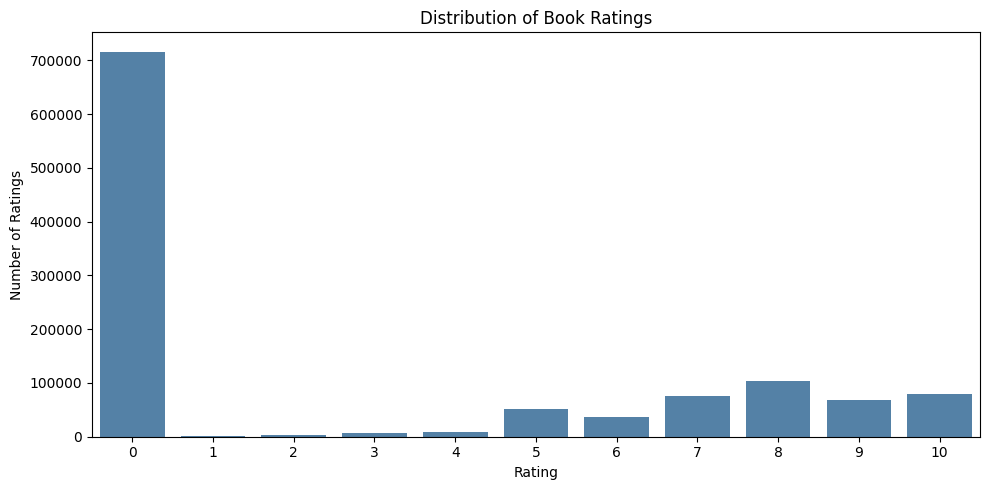

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=ratings_eda,
    x="Book-Rating",
    color="steelblue"
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()


Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Missing Ages: 110762
Invalid Ages (below 5 or above 100): 1248


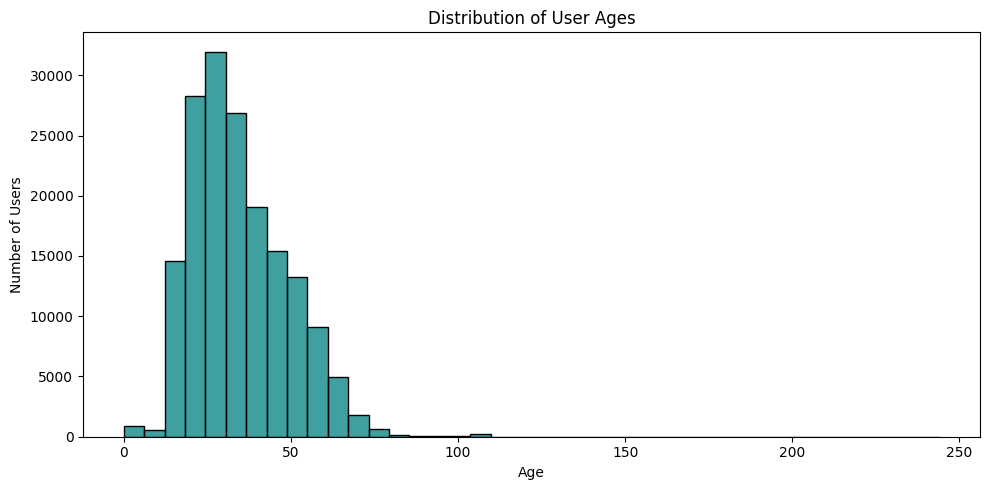

In [18]:

# ==========================================
# 2.4 USER AGE DISTRIBUTION
# ==========================================

ages = pd.to_numeric(users_eda["Age"], errors="coerce")

print("Age Statistics:")
print(ages.describe())

print("\nMissing Ages:", ages.isnull().sum())

invalid_ages = ((ages < 5) | (ages > 100)).sum()

print("Invalid Ages (below 5 or above 100):", invalid_ages)

plt.figure(figsize=(10, 5))

sns.histplot(
    ages.dropna(),
    bins=40,
    color="teal"
)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()


Publication Year Statistics:
count    255560.000000
mean       1958.462987
std         263.009881
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Missing Publication Years: 15819
Invalid Publication Years: 4531


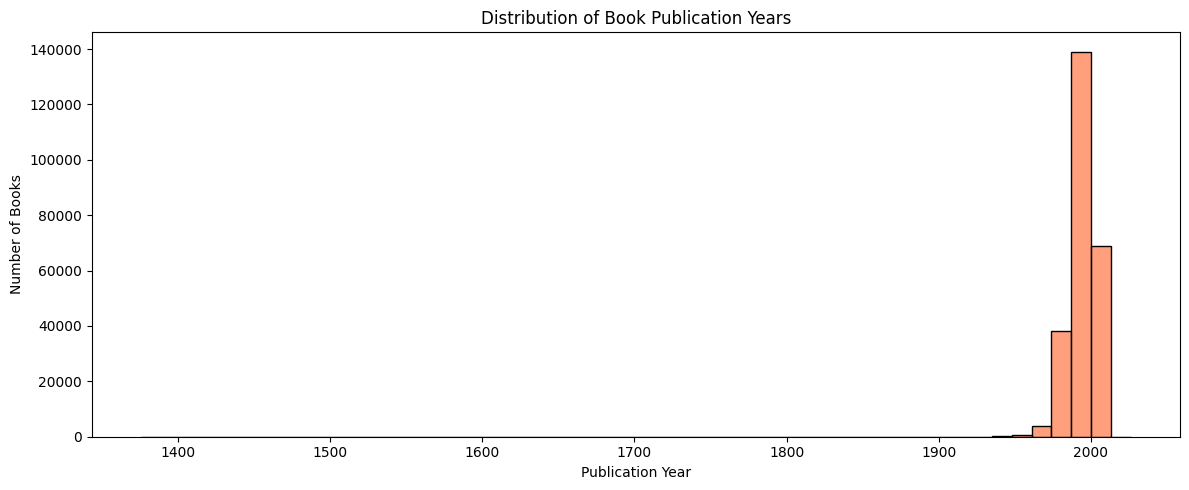

In [19]:

# ==========================================
# 2.5 PUBLICATION YEAR DISTRIBUTION
# ==========================================

current_year = datetime.now().year

pub_year = pd.to_numeric(
    books_eda["Year-Of-Publication"],
    errors="coerce"
)

print("Publication Year Statistics:")
print(pub_year.describe())

invalid_years = (
    (pub_year <= 0) | (pub_year > current_year)
).sum()

print("\nMissing Publication Years:", pub_year.isnull().sum())
print("Invalid Publication Years:", invalid_years)

plt.figure(figsize=(12, 5))

valid_years = pub_year[
    (pub_year > 0) & (pub_year <= current_year)
]

sns.histplot(
    valid_years,
    bins=50,
    color="coral"
)

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()


In [20]:

# ==========================================
# 2.6 RATINGS PER USER AND BOOK
# ==========================================

ratings_per_user = ratings_eda.groupby("User-ID").size()

ratings_per_book = ratings_eda.groupby("ISBN").size()

print("Ratings Per User:")
print(ratings_per_user.describe())

print("\nRatings Per Book:")
print(ratings_per_book.describe())

print("\nUsers with only one rating:",
      (ratings_per_user == 1).sum())

print("Books with only one rating:",
      (ratings_per_book == 1).sum())


Ratings Per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings Per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64

Users with only one rating: 59166
Books with only one rating: 197045


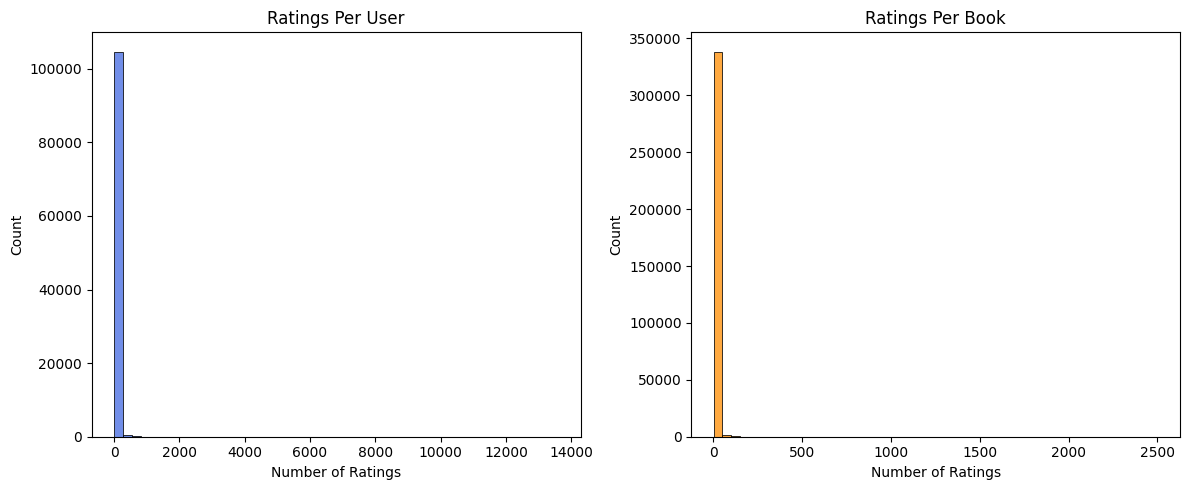

In [21]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(ratings_per_user, bins=50, color="royalblue")
plt.title("Ratings Per User")
plt.xlabel("Number of Ratings")

plt.subplot(1, 2, 2)
sns.histplot(ratings_per_book, bins=50, color="darkorange")
plt.title("Ratings Per Book")
plt.xlabel("Number of Ratings")

plt.tight_layout()
plt.show()


In [22]:

# ==========================================
# 2.7 USER-BOOK MATRIX SPARSITY
# ==========================================

total_users = ratings_eda["User-ID"].nunique()
total_books = ratings_eda["ISBN"].nunique()

total_possible_pairs = total_users * total_books

actual_pairs = ratings_eda[
    ["User-ID", "ISBN"]
].drop_duplicates().shape[0]

sparsity = (
    1 - actual_pairs / total_possible_pairs
) * 100

print("Unique Users:", total_users)
print("Unique Books:", total_books)
print("Total Possible User-Book Pairs:", total_possible_pairs)
print("Actual Rated User-Book Pairs:", actual_pairs)

print("\nMatrix Sparsity:", round(sparsity, 4), "%")
print("Matrix Density:", round(100 - sparsity, 4), "%")


Unique Users: 105283
Unique Books: 340556
Total Possible User-Book Pairs: 35854757348
Actual Rated User-Book Pairs: 1149780

Matrix Sparsity: 99.9968 %
Matrix Density: 0.0032 %



# EDA Findings and Observations

### 1. Dataset Structure and Missing Values
The datasets contain user, book, and rating information.
Missing values were identified in several columns. These will be handled appropriately in the Silver layer.

### 2. Rating Distribution
The dataset contains ratings from 0 to 10.
Zero ratings represent implicit feedback and will be removed because the recommender requires explicit ratings from 1 to 10.

### 3. User Age Distribution
The age column contains missing and potentially invalid values.
Ages below 5 and above 100 will be treated as invalid, and missing ages will be filled with the median.

### 4. Publication Year Distribution
Some publication years may be missing, zero, or in the future.
These invalid values will be converted to null values in the Silver layer.

### 5. Ratings Per User and Book
The rating distribution is expected to be uneven, with many users and books having very few ratings.
A minimum rating threshold will be selected to reduce sparsity and improve recommendation quality.

### 6. Matrix Sparsity
The user-book rating matrix is highly sparse because most users have rated only a small fraction of available books.
A sparse matrix will be used in the Gold layer to save memory.


In [23]:

# ==========================================
# STEP 3: SILVER LAYER - DATA CLEANING
# ==========================================

# Load data from Bronze layer

silver_users = pd.read_parquet("bronze/users.parquet")
silver_books = pd.read_parquet("bronze/books.parquet")
silver_ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze data loaded for Silver processing!")

print("Users:", silver_users.shape)
print("Books:", silver_books.shape)
print("Ratings:", silver_ratings.shape)


Bronze data loaded for Silver processing!
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [24]:

# ==========================================
# REMOVE DUPLICATE ROWS
# ==========================================

print("Duplicates before cleaning:")

print("Users:", silver_users.duplicated().sum())
print("Books:", silver_books.duplicated().sum())
print("Ratings:", silver_ratings.duplicated().sum())

# Remove exact duplicate rows

silver_users = silver_users.drop_duplicates().copy()
silver_books = silver_books.drop_duplicates().copy()
silver_ratings = silver_ratings.drop_duplicates().copy()

# Ensure unique user and book lookup records
silver_users = silver_users.drop_duplicates(
    subset=["User-ID"], keep="first"
)

silver_books = silver_books.drop_duplicates(
    subset=["ISBN"], keep="first"
)

print("\nDuplicates removed successfully!")

print("Users:", silver_users.shape)
print("Books:", silver_books.shape)
print("Ratings:", silver_ratings.shape)


Duplicates before cleaning:
Users: 0
Books: 0
Ratings: 0

Duplicates removed successfully!
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [25]:

# ==========================================
# CLEAN RATINGS
# ==========================================

silver_ratings["Book-Rating"] = pd.to_numeric(
    silver_ratings["Book-Rating"],
    errors="coerce"
)

before_ratings = len(silver_ratings)

silver_ratings = silver_ratings[
    silver_ratings["Book-Rating"].between(1, 10)
].copy()

print("Ratings before cleaning:", before_ratings)
print("Ratings after cleaning:", len(silver_ratings))

print("Zero ratings remaining:",
      (silver_ratings["Book-Rating"] == 0).sum())

print("\nRating distribution:")
print(silver_ratings["Book-Rating"].value_counts().sort_index())


Ratings before cleaning: 1149780
Ratings after cleaning: 433671
Zero ratings remaining: 0

Rating distribution:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


In [26]:

# ==========================================
# CLEAN USER AGES
# ==========================================

silver_users["Age"] = pd.to_numeric(
    silver_users["Age"],
    errors="coerce"
)

# Replace impossible ages with null
silver_users.loc[
    (silver_users["Age"] < 5) |
    (silver_users["Age"] > 100),
    "Age"
] = np.nan

# Calculate median age
median_age = silver_users["Age"].median()

# Fill missing ages with median
silver_users["Age"] = silver_users["Age"].fillna(
    median_age
)

print("Median age:", median_age)
print("Missing ages remaining:", silver_users["Age"].isna().sum())

print("\nAge statistics:")
print(silver_users["Age"].describe())


Median age: 32.0
Missing ages remaining: 0

Age statistics:
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64


In [27]:

# ==========================================
# SPLIT USER LOCATION
# ==========================================

location_parts = (
    silver_users["Location"]
    .fillna("")
    .astype(str)
    .str.split(",", n=2, expand=True)
)

# Ensure exactly three location columns
location_parts = location_parts.reindex(
    columns=range(3)
)

silver_users["City"] = location_parts[0]
silver_users["State"] = location_parts[1]
silver_users["Country"] = location_parts[2]

# Remove unnecessary spaces
for col in ["City", "State", "Country"]:
    silver_users[col] = (
        silver_users[col]
        .str.strip()
        .replace("", np.nan)
        .str.title()
    )

# Remove original combined Location column
silver_users.drop(columns=["Location"], inplace=True)

print("Location split successfully!")

display(
    silver_users[
        ["User-ID", "City", "State", "Country", "Age"]
    ].head(10)
)


Location split successfully!


,User-ID,City,State,Country,Age
0,1,Nyc,New York,Usa,32.0
1,2,Stockton,California,Usa,18.0
2,3,Moscow,Yukon Territory,Russia,32.0
3,4,Porto,V.N.Gaia,Portugal,17.0
4,5,Farnborough,Hants,United Kingdom,32.0
5,6,Santa Monica,California,Usa,61.0
6,7,Washington,Dc,Usa,32.0
7,8,Timmins,Ontario,Canada,32.0
8,9,Germantown,Tennessee,Usa,32.0
9,10,Albacete,Wisconsin,Spain,26.0


In [28]:

# ==========================================
# CLEAN PUBLICATION YEARS
# ==========================================

current_year = datetime.now().year

silver_books["Year-Of-Publication"] = pd.to_numeric(
    silver_books["Year-Of-Publication"],
    errors="coerce"
)

# Replace zero and future publication years with null
invalid_year_mask = (
    (silver_books["Year-Of-Publication"] <= 0) |
    (silver_books["Year-Of-Publication"] > current_year)
)

invalid_year_count = invalid_year_mask.sum()

silver_books.loc[
    invalid_year_mask,
    "Year-Of-Publication"
] = np.nan

print("Invalid publication years replaced:", invalid_year_count)
print("Missing publication years:",
      silver_books["Year-Of-Publication"].isna().sum())


Invalid publication years replaced: 4531
Missing publication years: 20350


In [29]:

# ==========================================
# CLEAN TEXT COLUMNS
# ==========================================

# Remove image URL columns
image_columns = [
    col for col in silver_books.columns
    if col.lower().startswith("image-url")
]

silver_books.drop(
    columns=image_columns,
    inplace=True,
    errors="ignore"
)

# Clean book text columns
book_text_columns = [
    "Book-Title",
    "Book-Author",
    "Publisher"
]

for col in book_text_columns:
    silver_books[col] = (
        silver_books[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

# Clean user location text
for col in ["City", "State", "Country"]:
    silver_users[col] = (
        silver_users[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

# Clean ISBN identifiers without changing their case
silver_books["ISBN"] = (
    silver_books["ISBN"].astype("string").str.strip()
)

print("Text cleaning completed!")
print("Remaining book columns:")
print(silver_books.columns.tolist())

display(silver_books.head())


Text cleaning completed!
Remaining book columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'ingestion_timestamp']


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002.0,Oxford University Press,2026-11-24 10:12:53.862597+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001.0,Harperflamingo Canada,2026-11-24 10:12:53.862597+00:00
2,0060973129,Decision In Normandy,Carlo D'Este,1991.0,Harperperennial,2026-11-24 10:12:53.862597+00:00
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999.0,Farrar Straus Giroux,2026-11-24 10:12:53.862597+00:00
4,0393045218,"The Mummies Of Urumchi"";""E. J. W. Barber",1999,NaN,Company,2026-11-24 10:12:53.862597+00:00


In [30]:

# ==========================================
# VALIDATE USER AND BOOK REFERENCES
# ==========================================

# Ensure consistent identifier types
silver_users["User-ID"] = pd.to_numeric(
    silver_users["User-ID"], errors="coerce"
)

silver_ratings["User-ID"] = pd.to_numeric(
    silver_ratings["User-ID"], errors="coerce"
)

silver_ratings["ISBN"] = (
    silver_ratings["ISBN"].astype("string").str.strip()
)

# Remove records with missing identifiers
silver_users = silver_users.dropna(
    subset=["User-ID"]
).copy()

silver_books = silver_books.dropna(
    subset=["ISBN"]
).copy()

silver_ratings = silver_ratings.dropna(
    subset=["User-ID", "ISBN"]
).copy()

# Retain ratings only if user and book exist
valid_user_ids = set(silver_users["User-ID"])
valid_book_ids = set(silver_books["ISBN"])

before = len(silver_ratings)

silver_ratings = silver_ratings[
    silver_ratings["User-ID"].isin(valid_user_ids) &
    silver_ratings["ISBN"].isin(valid_book_ids)
].copy()

print("Ratings before reference validation:", before)
print("Ratings after reference validation:", len(silver_ratings))
print("Invalid references remaining:",
      len(silver_ratings) - len(
          silver_ratings[
              silver_ratings["User-ID"].isin(valid_user_ids) &
              silver_ratings["ISBN"].isin(valid_book_ids)
          ]
      ))


Ratings before reference validation: 433671
Ratings after reference validation: 383853
Invalid references remaining: 0


In [31]:

# ==========================================
# FILTER USERS AND BOOKS BY RATING COUNT
# ==========================================

MIN_RATINGS = 10

initial_ratings = len(silver_ratings)

while True:

    # Count ratings per user and book
    user_counts = silver_ratings.groupby("User-ID").size()
    book_counts = silver_ratings.groupby("ISBN").size()

    # Identify sufficiently active users and books
    valid_users = user_counts[
        user_counts >= MIN_RATINGS
    ].index

    valid_books = book_counts[
        book_counts >= MIN_RATINGS
    ].index

    # Filter ratings
    filtered_ratings = silver_ratings[
        silver_ratings["User-ID"].isin(valid_users) &
        silver_ratings["ISBN"].isin(valid_books)
    ].copy()

    # Stop when filtering no longer changes the data
    if len(filtered_ratings) == len(silver_ratings):
        break

    silver_ratings = filtered_ratings

# Keep only users and books present in final ratings
silver_users = silver_users[
    silver_users["User-ID"].isin(
        silver_ratings["User-ID"].unique()
    )
].copy()

silver_books = silver_books[
    silver_books["ISBN"].isin(
        silver_ratings["ISBN"].unique()
    )
].copy()

print("Minimum rating threshold:", MIN_RATINGS)
print("Initial ratings:", initial_ratings)
print("Final ratings:", len(silver_ratings))
print("Final users:", len(silver_users))
print("Final books:", len(silver_books))

print("\nMinimum user ratings:",
      silver_ratings.groupby("User-ID").size().min())

print("Minimum book ratings:",
      silver_ratings.groupby("ISBN").size().min())


Minimum rating threshold: 10
Initial ratings: 383853
Final ratings: 41456
Final users: 1820
Final books: 2030

Minimum user ratings: 10
Minimum book ratings: 10


In [32]:

# ==========================================
# SAVE SILVER LAYER
# ==========================================

silver_users.to_parquet(
    "silver/users_silver.parquet",
    index=False
)

silver_books.to_parquet(
    "silver/books_silver.parquet",
    index=False
)

silver_ratings.to_parquet(
    "silver/ratings_silver.parquet",
    index=False
)

print("Silver Layer created successfully!")

print("\nSilver folder contents:")
print(os.listdir("silver"))


Silver Layer created successfully!

Silver folder contents:
['books_silver.parquet', 'users_silver.parquet', 'ratings_silver.parquet']


In [33]:

# ==========================================
# SILVER LAYER VERIFICATION
# ==========================================

check_users = pd.read_parquet(
    "silver/users_silver.parquet"
)

check_books = pd.read_parquet(
    "silver/books_silver.parquet"
)

check_ratings = pd.read_parquet(
    "silver/ratings_silver.parquet"
)

print("========== SILVER LAYER SUMMARY ==========")

print("\nUsers:", check_users.shape)
print("Books:", check_books.shape)
print("Ratings:", check_ratings.shape)

print("\nMissing values in Users:")
print(check_users.isnull().sum())

print("\nMissing values in Books:")
print(check_books.isnull().sum())

print("\nZero ratings remaining:",
      (check_ratings["Book-Rating"] == 0).sum())

print("\nSilver files:")
print(os.listdir("silver"))


========== SILVER LAYER SUMMARY ==========

Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)

Missing values in Users:
User-ID                 0
Age                     0
ingestion_timestamp     0
City                    1
State                  45
Country                61
dtype: int64

Missing values in Books:
ISBN                    0
Book-Title              0
Book-Author             0
Year-Of-Publication    41
Publisher               0
ingestion_timestamp     0
dtype: int64

Zero ratings remaining: 0

Silver files:
['books_silver.parquet', 'users_silver.parquet', 'ratings_silver.parquet']



# Step 3: Silver Layer – Data Cleaning

The Silver layer contains cleaned and validated datasets derived from the Bronze layer.

The following operations were performed:

1. Removed duplicate records from users, books and ratings.
2. Removed zero ratings and retained explicit ratings between 1 and 10.
3. Replaced invalid user ages (below 5 or above 100) with null values and filled missing ages using the median.
4. Split user locations into city, state and country.
5. Replaced invalid publication years, including zero and future years, with null values.
6. Standardized text columns by removing extra spaces and applying title case.
7. Removed unnecessary image URL columns.
8. Removed ratings referencing nonexistent users or books.
9. Retained users and books having at least 10 ratings.

The cleaned datasets were saved in Parquet format inside the silver/ directory.


In [34]:

# ==========================================
# FINAL SILVER LAYER VERIFICATION
# ==========================================

users_s = pd.read_parquet("silver/users_silver.parquet")
books_s = pd.read_parquet("silver/books_silver.parquet")
ratings_s = pd.read_parquet("silver/ratings_silver.parquet")

print("========== SILVER LAYER SUMMARY ==========")

print("\nUsers:", users_s.shape)
print("Books:", books_s.shape)
print("Ratings:", ratings_s.shape)

print("\nMinimum ratings per user:",
      ratings_s.groupby("User-ID").size().min())

print("Minimum ratings per book:",
      ratings_s.groupby("ISBN").size().min())

print("\nZero ratings:",
      (ratings_s["Book-Rating"] == 0).sum())

print("\nDuplicate user-book pairs:",
      ratings_s.duplicated(["User-ID", "ISBN"]).sum())

print("\nSilver files:", os.listdir("silver"))


========== SILVER LAYER SUMMARY ==========

Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)

Minimum ratings per user: 10
Minimum ratings per book: 10

Zero ratings: 0

Duplicate user-book pairs: 0

Silver files: ['books_silver.parquet', 'users_silver.parquet', 'ratings_silver.parquet']


In [35]:

# ==========================================
# STEP 4: BUILD GOLD LAYER
# ==========================================

import os
import numpy as np
import pandas as pd

# Load Silver datasets
users_gold = pd.read_parquet(
    "silver/users_silver.parquet"
)

books_gold = pd.read_parquet(
    "silver/books_silver.parquet"
)

ratings_gold = pd.read_parquet(
    "silver/ratings_silver.parquet"
)

# Create Gold folder
os.makedirs("gold", exist_ok=True)

print("Silver datasets loaded successfully!")

print("Users:", users_gold.shape)
print("Books:", books_gold.shape)
print("Ratings:", ratings_gold.shape)


Silver datasets loaded successfully!
Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)


In [36]:

# ==========================================
# CREATE BOOK LOOKUP TABLE
# ==========================================

book_lookup = books_gold[
    ["ISBN", "Book-Title", "Book-Author"]
].copy()

book_lookup = book_lookup.rename(columns={
    "ISBN": "book_id",
    "Book-Title": "title",
    "Book-Author": "author"
})

book_lookup.to_parquet(
    "gold/book_lookup.parquet",
    index=False
)

print("Book lookup table created!")
display(book_lookup.head(10))

print("Total books:", len(book_lookup))


Book lookup table created!


,book_id,title,author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,Michael Crichton
5,0446310786,"To Kill A Mockingbird"";""Harper Lee",1988
6,0449005615,Seabiscuit: An American Legend,Laura Hillenbrand
7,0671888587,I'Ll Be Seeing You,Mary Higgins Clark
8,0553582747,From The Corner Of His Eye,Dean Koontz
9,0425182908,Isle Of Dogs,Patricia Cornwell


Total books: 2030


In [37]:

# ==========================================
# CREATE USER AND BOOK INDEX MAPPINGS
# ==========================================

user_ids = sorted(ratings_gold["User-ID"].unique())
book_ids = sorted(ratings_gold["ISBN"].unique())

user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

book_to_idx = {
    book_id: idx
    for idx, book_id in enumerate(book_ids)
}

# Save mappings
user_mapping = pd.DataFrame({
    "User-ID": user_ids,
    "user_index": range(len(user_ids))
})

book_mapping = pd.DataFrame({
    "ISBN": book_ids,
    "book_index": range(len(book_ids))
})

user_mapping.to_csv(
    "gold/user_mapping.csv",
    index=False
)

book_mapping.to_csv(
    "gold/book_mapping.csv",
    index=False
)

print("ID mappings created successfully!")

print("Unique users:", len(user_ids))
print("Unique books:", len(book_ids))


ID mappings created successfully!
Unique users: 1820
Unique books: 2030


In [38]:

# ==========================================
# CREATE SPARSE RATING MATRIX
# ==========================================

from scipy.sparse import csr_matrix, save_npz

# Convert actual user and book IDs into matrix indices
row_indices = ratings_gold["ISBN"].map(book_to_idx).to_numpy()
col_indices = ratings_gold["User-ID"].map(user_to_idx).to_numpy()

rating_values = ratings_gold["Book-Rating"].to_numpy(
    dtype=np.float32
)

# Rows = Books, Columns = Users
rating_matrix = csr_matrix(
    (
        rating_values,
        (row_indices, col_indices)
    ),
    shape=(len(book_ids), len(user_ids)),
    dtype=np.float32
)

# Save sparse matrix
save_npz(
    "gold/rating_matrix.npz",
    rating_matrix
)

print("Sparse rating matrix created successfully!")

print("Matrix shape:", rating_matrix.shape)
print("Number of stored ratings:", rating_matrix.nnz)
print("Matrix format:", rating_matrix.format)


Sparse rating matrix created successfully!
Matrix shape: (2030, 1820)
Number of stored ratings: 41456
Matrix format: csr


In [39]:

# ==========================================
# USER-LEVEL AGGREGATES
# ==========================================

user_aggregates = (
    ratings_gold.groupby("User-ID")["Book-Rating"]
    .agg(
        average_rating="mean",
        number_of_ratings="count"
    )
    .reset_index()
)

user_aggregates["average_rating"] = (
    user_aggregates["average_rating"].round(2)
)

user_aggregates.to_parquet(
    "gold/user_aggregates.parquet",
    index=False
)

print("User aggregates created successfully!")

display(user_aggregates.head(10))


User aggregates created successfully!


,User-ID,average_rating,number_of_ratings
0,243,7.77,13
1,254,8.45,20
2,638,9.45,22
3,805,8.40,10
4,882,8.24,17
5,1131,6.86,14
6,1424,7.18,11
7,1435,6.62,13
8,1733,7.18,11
9,1848,8.60,10


In [40]:

# ==========================================
# BOOK-LEVEL AGGREGATES
# ==========================================

book_aggregates = (
    ratings_gold.groupby("ISBN")["Book-Rating"]
    .agg(
        average_rating="mean",
        number_of_ratings="count"
    )
    .reset_index()
)

book_aggregates["average_rating"] = (
    book_aggregates["average_rating"].round(2)
)

book_aggregates.to_parquet(
    "gold/book_aggregates.parquet",
    index=False
)

print("Book aggregates created successfully!")

display(book_aggregates.head(10))


Book aggregates created successfully!


,ISBN,average_rating,number_of_ratings
0,0020199600,8.17,12
1,0020442203,8.83,12
2,002542730X,7.48,27
3,0028604199,7.90,10
4,0060002050,7.55,11
5,006000438X,7.28,18
6,0060008032,7.39,18
7,006001203X,8.09,11
8,0060085444,7.08,12
9,0060085452,8.11,18


In [41]:

# ==========================================
# GOLD LAYER VERIFICATION
# ==========================================

from scipy.sparse import load_npz

# Load saved matrix
check_matrix = load_npz(
    "gold/rating_matrix.npz"
)

# Load saved tables
check_lookup = pd.read_parquet(
    "gold/book_lookup.parquet"
)

check_user_agg = pd.read_parquet(
    "gold/user_aggregates.parquet"
)

check_book_agg = pd.read_parquet(
    "gold/book_aggregates.parquet"
)

print("========== GOLD LAYER SUMMARY ==========")

print("\nRating Matrix:", check_matrix.shape)
print("Stored Ratings:", check_matrix.nnz)

print("\nBook Lookup:", check_lookup.shape)
print("User Aggregates:", check_user_agg.shape)
print("Book Aggregates:", check_book_agg.shape)

print("\nGold Folder Files:")
print(os.listdir("gold"))

print("\nGold Layer created and verified successfully!")


========== GOLD LAYER SUMMARY ==========

Rating Matrix: (2030, 1820)
Stored Ratings: 41456

Book Lookup: (2030, 3)
User Aggregates: (1820, 3)
Book Aggregates: (2030, 3)

Gold Folder Files:
['book_lookup.parquet', 'rating_matrix.npz', 'book_aggregates.parquet', 'user_mapping.csv', 'user_aggregates.parquet', 'book_mapping.csv']

Gold Layer created and verified successfully!


In [42]:

# ==========================================
# SPARSE MATRIX DENSITY
# ==========================================

total_cells = rating_matrix.shape[0] * rating_matrix.shape[1]

density = (rating_matrix.nnz / total_cells) * 100
sparsity = 100 - density

print("Total matrix cells:", total_cells)
print("Actual ratings:", rating_matrix.nnz)
print("Matrix density:", round(density, 4), "%")
print("Matrix sparsity:", round(sparsity, 4), "%")


Total matrix cells: 3694600
Actual ratings: 41456
Matrix density: 1.1221 %
Matrix sparsity: 98.8779 %



# Step 4: Gold Layer – Model-Ready Data

The Gold layer contains model-ready data generated from the cleaned Silver datasets.

The following components were created:

1. A sparse user-book rating matrix using SciPy CSR format, with books as rows and users as columns.
2. A book lookup table containing ISBN, book title and author.
3. User-level aggregates containing average rating and total number of ratings.
4. Book-level aggregates containing average rating and total number of ratings.
5. User and book index mappings to connect original identifiers with matrix positions.

The sparse matrix reduces memory usage by storing only actual ratings instead of empty user-book combinations.

All Gold datasets were saved in the gold/ directory in appropriate formats.


In [43]:

# ==========================================
# STEP 5: ITEM-BASED COLLABORATIVE FILTERING
# ==========================================

import pandas as pd
import numpy as np

from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors

# Load sparse rating matrix
rating_matrix = load_npz("gold/rating_matrix.npz")

# Load book lookup and mappings
book_lookup = pd.read_parquet("gold/book_lookup.parquet")

book_mapping = pd.read_csv(
    "gold/book_mapping.csv",
    dtype={"ISBN": str}
)

# Load cleaned ratings
ratings_gold = pd.read_parquet(
    "silver/ratings_silver.parquet"
)

# Create index mappings
book_to_idx = dict(
    zip(book_mapping["ISBN"], book_mapping["book_index"])
)

idx_to_book = dict(
    zip(book_mapping["book_index"], book_mapping["ISBN"])
)

print("Gold data loaded successfully!")
print("Rating matrix:", rating_matrix.shape)
print("Book lookup:", book_lookup.shape)


Gold data loaded successfully!
Rating matrix: (2030, 1820)
Book lookup: (2030, 3)


In [44]:

# ==========================================
# BUILD COSINE SIMILARITY MODEL
# ==========================================

model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

# Train model on sparse book-user matrix
model.fit(rating_matrix)

print("Cosine similarity model trained successfully!")


Cosine similarity model trained successfully!


In [45]:

# ==========================================
# FIND 10 MOST SIMILAR BOOKS
# ==========================================

def find_similar_books(book_title, n=10):

    # Find book using title
    matches = book_lookup[
        book_lookup["title"].astype(str).str.strip().str.casefold()
        == str(book_title).strip().casefold()
    ]

    if matches.empty:
        print("Book not found!")
        return pd.DataFrame()

    # Select first matching book
    isbn = str(matches.iloc[0]["book_id"])

    if isbn not in book_to_idx:
        print("Book not available in rating matrix!")
        return pd.DataFrame()

    book_idx = book_to_idx[isbn]

    # Find nearest books
    distances, indices = model.kneighbors(
        rating_matrix[book_idx],
        n_neighbors=min(n + 1, rating_matrix.shape[0])
    )

    results = []

    for distance, idx in zip(distances[0], indices[0]):

        if idx == book_idx:
            continue

        similar_isbn = idx_to_book[idx]

        similarity = 1 - distance

        book_info = book_lookup[
            book_lookup["book_id"].astype(str) == str(similar_isbn)
        ]

        if not book_info.empty:
            results.append({
                "Book Title": book_info.iloc[0]["title"],
                "Author": book_info.iloc[0]["author"],
                "Similarity": round(float(similarity), 4)
            })

        if len(results) == n:
            break

    return pd.DataFrame(results)


print("Similar book function created successfully!")


Similar book function created successfully!


In [46]:

# Display sample book titles

display(
    book_lookup[["title", "author"]].head(15)
)


,title,author
0,The Testament,John Grisham
1,Beloved (Plume Contemporary Fiction),Toni Morrison
2,Wild Animus,Rich Shapero
3,Airframe,Michael Crichton
4,Timeline,Michael Crichton
5,"To Kill A Mockingbird"";""Harper Lee",1988
6,Seabiscuit: An American Legend,Laura Hillenbrand
7,I'Ll Be Seeing You,Mary Higgins Clark
8,From The Corner Of His Eye,Dean Koontz
9,Isle Of Dogs,Patricia Cornwell


In [47]:

# Test similar book recommendations

test_title = book_lookup.iloc[0]["title"]

print("Selected Book:", test_title)

similar_books = find_similar_books(
    test_title,
    n=10
)

display(similar_books)


Selected Book: The Testament


,Book Title,Author,Similarity
0,Monster : A Novel (Alex Delaware Novels (Paper...,Jonathan Kellerman,0.2528
1,The Runaway Jury,John Grisham,0.2378
2,The Bone Collector (Lincoln Rhyme Novels (Pape...,Jeff Deaver,0.2376
3,Call Of The Wild,Jack London,0.2359
4,The Simple Truth,David Baldacci,0.2356
5,The Street Lawyer,John Grisham,0.2198
6,Atlantis Found,Clive Cussler,0.1994
7,Outbreak,Robin Cook,0.1987
8,From Potter'S Field,Patricia Daniels Cornwell,0.1962
9,Writ Of Execution,Perri O'Shaughnessy,0.1901


In [48]:

# ==========================================
# MAIN RECOMMENDATION FUNCTION
# ==========================================

def recommend(user_id, n=10):

    # Get ratings of selected user
    user_data = ratings_gold[
        ratings_gold["User-ID"] == user_id
    ].copy()

    if user_data.empty:
        print("User not found!")
        return pd.DataFrame()

    # Books already read by user
    read_books = set(user_data["ISBN"].astype(str))

    # Select highly rated books
    liked_books = user_data[
        user_data["Book-Rating"] >= 7
    ].sort_values(
        "Book-Rating",
        ascending=False
    )

    if liked_books.empty:
        print("User has no highly rated books!")
        return pd.DataFrame()

    # Store weighted recommendation scores
    scores = {}

    for _, row in liked_books.iterrows():

        isbn = str(row["ISBN"])

        if isbn not in book_to_idx:
            continue

        book_idx = book_to_idx[isbn]

        # Find similar books
        distances, indices = model.kneighbors(
            rating_matrix[book_idx],
            n_neighbors=11
        )

        user_rating = float(row["Book-Rating"])

        for distance, idx in zip(
            distances[0],
            indices[0]
        ):

            candidate_isbn = str(idx_to_book[idx])

            # Skip books already read
            if candidate_isbn in read_books:
                continue

            similarity = 1 - float(distance)

            if similarity <= 0:
                continue

            weighted_score = similarity * user_rating

            if candidate_isbn not in scores:
                scores[candidate_isbn] = [0.0, 0.0]

            scores[candidate_isbn][0] += weighted_score
            scores[candidate_isbn][1] += similarity

    # Calculate final weighted scores
    results = []

    for isbn, (total_score, total_similarity) in scores.items():

        if total_similarity == 0:
            continue

        final_score = total_score / total_similarity

        book_info = book_lookup[
            book_lookup["book_id"].astype(str) == isbn
        ]

        if book_info.empty:
            continue

        results.append({
            "ISBN": isbn,
            "Book Title": book_info.iloc[0]["title"],
            "Author": book_info.iloc[0]["author"],
            "Recommendation Score": round(final_score, 4)
        })

    # Sort recommendations by score
    recommendations = pd.DataFrame(results)

    if recommendations.empty:
        return recommendations

    recommendations = recommendations.sort_values(
        "Recommendation Score",
        ascending=False
    )

    return recommendations.head(n).reset_index(drop=True)


print("Main recommendation function created successfully!")


Main recommendation function created successfully!



# Step 5: Item-Based Collaborative Filtering

An item-based collaborative filtering recommendation system was implemented using cosine similarity.

The sparse book-user rating matrix was loaded from the Gold layer.

Scikit-learn's NearestNeighbors algorithm was used with cosine distance to identify similar books.

Two recommendation functions were implemented:

1. find_similar_books(book_title, n=10): Returns the most similar books for a given book title.
2. recommend(user_id, n=10): Recommends books based on the user's highly rated books.

The recommendation score is calculated using the similarity between books weighted by the user's ratings.

Books already rated by the user are excluded from the final recommendations.


In [49]:

# ==========================================
# STEP 6: DEMO AND SANITY CHECK
# ==========================================

# Find users who have rated books 7 or above

high_rated_users = (
    ratings_gold[
        ratings_gold["Book-Rating"] >= 7
    ]
    .groupby("User-ID")
    .size()
    .sort_values(ascending=False)
)

# Select three different users
test_users = high_rated_users.head(3).index.tolist()

print("Selected Test Users:", test_users)

for uid in test_users:
    print(
        f"User {uid}:",
        high_rated_users.loc[uid],
        "highly rated books"
    )


Selected Test Users: [11676, 16795, 104636]
User 11676: 736 highly rated books
User 16795: 200 highly rated books
User 104636: 180 highly rated books


In [50]:

# ==========================================
# TEST RECOMMENDATIONS FOR THREE USERS
# ==========================================

for uid in test_users:

    print("\n" + "=" * 70)
    print("USER ID:", uid)
    print("=" * 70)

    # Get highly rated books
    liked = ratings_gold[
        (ratings_gold["User-ID"] == uid) &
        (ratings_gold["Book-Rating"] >= 7)
    ].sort_values(
        "Book-Rating",
        ascending=False
    ).head(5)

    # Display highly rated books
    print("\nBOOKS RATED HIGHLY BY USER:")

    liked_display = liked.merge(
        book_lookup,
        left_on="ISBN",
        right_on="book_id",
        how="left"
    )

    display(
        liked_display[
            ["Book-Title"] if "Book-Title" in liked_display.columns
            else ["title", "author", "Book-Rating"]
        ]
        if "Book-Title" in liked_display.columns
        else liked_display[["title", "author", "Book-Rating"]]
    )

    # Generate recommendations
    print("\nRECOMMENDED BOOKS:")

    recommendations = recommend(uid, n=10)

    if recommendations.empty:
        print("No recommendations available for this user.")
    else:
        display(recommendations)



USER ID: 11676

BOOKS RATED HIGHLY BY USER:


,title,author,Book-Rating
0,The Time Traveler'S Wife,Audrey Niffenegger,10
1,The Time Traveler'S Wife (Today Show Book Club...,Audrey Niffenegger,10
2,Message From Nam,Danielle Steel,10
3,Mixed Blessings,Danielle Steel,10
4,Echoes,Maeve Binchy,10



RECOMMENDED BOOKS:


,ISBN,Book Title,Author,Recommendation Score
0,0060256656,The Giving Tree,Shel Silverstein,10.0
1,089480829X,What To Expect When You'Re Expecting (Revised ...,Arlene Eisenberg,10.0
2,0805063889,Nickel And Dimed: On (Not) Getting By In America,Barbara Ehrenreich,10.0
3,0842332286,The Mark: The Beast Rules The World (Left Behi...,Tim Lahaye,10.0
4,0064471063,The Horse And His Boy,C. S. Lewis,10.0
5,0064471055,Prince Caspian (Rack) : The Return To Narnia (...,C. S. Lewis,10.0
6,006447108X,The Last Battle,C. S. Lewis,10.0
7,067976397X,Corelli'S Mandolin : A Novel,Louis De Bernieres,10.0
8,0375500510,Black And Blue : A Novel,Anna Quindlen,10.0
9,0684863472,A Heartbreaking Work Of Staggering Genius : A ...,2000,10.0



USER ID: 16795

BOOKS RATED HIGHLY BY USER:


,title,author,Book-Rating
0,The Dive From Clausen'S Pier (Alex Awards),Ann Packer,10
1,How Reading Changed My Life (Library Of Contem...,Anna Quindlen,10
2,The Lovely Bones: A Novel,Alice Sebold,10
3,The Dogs Of Babel (Today Show Book Club #12),Carolyn Parkhurst,10
4,The Secret Life Of Bees,Sue Monk Kidd,10


... (2 outputs left out)


USER ID: 104636

BOOKS RATED HIGHLY BY USER:


,title,author,Book-Rating
0,Where The Sidewalk Ends : Poems And Drawings,Shel Silverstein,10
1,Bridge To Terabithia,Katherine Paterson,10
2,"The Lion, The Witch, And The Wardrobe (The Chr...",C. S. Lewis,10
3,Little House On The Prairie,Laura Ingalls Wilder,10
4,Charlotte'S Web (Trophy Newbery),E. B. White,10



RECOMMENDED BOOKS:


,ISBN,Book Title,Author,Recommendation Score
0,0385502532,Drowning Ruth,Christina Schwarz,10.0
1,0671027573,Mr. Perfect,Linda Howard,10.0
2,0590353403,Harry Potter And The Sorcerer'S Stone (Book 1),J. K. Rowling,10.0
3,0439064864,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,10.0
4,0440901588,A Swiftly Tilting Planet,Madeleine L'Engle,10.0
5,0439404371,The Thief Lord,Cornelia Funke,10.0
6,043936213X,Harry Potter And The Sorcerer'S Stone (Book 1),J. K. Rowling,10.0
7,0439139597,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,10.0
8,043935806X,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,10.0
9,037582233X,Stargirl,Jerry Spinelli,10.0


In [51]:

# ==========================================
# RECOMMENDATION SANITY CHECK
# ==========================================

for uid in test_users:

    recs = recommend(uid, n=10)

    # Books already rated by the user
    already_read = set(
        ratings_gold.loc[
            ratings_gold["User-ID"] == uid,
            "ISBN"
        ].astype(str)
    )

    recommended_ids = set(recs["ISBN"].astype(str))

    print("\nUser:", uid)

    print("Recommendations generated:", len(recs))

    print(
        "Duplicate recommendations:",
        recs["ISBN"].duplicated().sum()
    )

    print(
        "Previously read books recommended:",
        len(recommended_ids & already_read)
    )

    print(
        "All books exist in lookup:",
        recommended_ids.issubset(
            set(book_lookup["book_id"].astype(str))
        )
    )

    assert recs["ISBN"].duplicated().sum() == 0
    assert len(recommended_ids & already_read) == 0
    assert recommended_ids.issubset(
        set(book_lookup["book_id"].astype(str))
    )

print("\nAll sanity checks passed!")



User: 11676
Recommendations generated: 10
Duplicate recommendations: 0
Previously read books recommended: 0
All books exist in lookup: True

User: 16795
Recommendations generated: 10
Duplicate recommendations: 0
Previously read books recommended: 0
All books exist in lookup: True

User: 104636
Recommendations generated: 10
Duplicate recommendations: 0
Previously read books recommended: 0
All books exist in lookup: True

All sanity checks passed!



# Step 6: Demo and Sanity Check

The recommendation system was tested using three different users from the Silver dataset.

For each user:
1. The books rated 7 or above were identified.
2. Similar books were found using cosine similarity.
3. Recommendations were ranked using a weighted similarity score.
4. Books already rated by the user were excluded.

The system successfully generated personalized book recommendations.

Sanity checks were performed to verify that:
- Recommended books were not previously rated by the user.
- No duplicate recommendations were generated.
- Every recommended book existed in the book lookup table.
